# 08 · DDColor: colorization of black-and-white photographs

**What it is.** DDColor (Kang et al., ICCV 2023, `ddcolor_paper.bin`, 870 MB, Apache-2.0): dual-decoder colorization of a grayscale picture. Used only when a photograph is detected as black-and-white.

**How it is scored (ground truth).** Colourful public photographs are converted to grayscale, colorized by DDColor, and compared with the original colours in CIE-Lab: **mean absolute error of the chroma channels (a, b)** (lower is closer), **colorfulness** (Hasler-Susstrunk, closer to the original is better), against the baseline "leave it gray". Colorization has many valid answers, so the absolute error is expected to be non-zero; the point is whether the model moves toward the truth.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


In [2]:
from enhancement.colorize import colorize_with_ddcolor

def colorfulness(image):
    b, g, r = [c.astype(np.float32) for c in cv2.split(image)]
    rg, yb = r - g, 0.5 * (r + g) - b
    return float(np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2))

def ab_mae(truth, other):
    a, b = cv2.cvtColor(truth, cv2.COLOR_BGR2LAB)[..., 1:].astype(np.float32), cv2.cvtColor(other, cv2.COLOR_BGR2LAB)[..., 1:].astype(np.float32)
    return float(np.mean(np.abs(a - b)))

pool = sorted(public_stock_ids(), key=lambda pk: -colorfulness(photo(pk, 400)))[:12][::2]
rows, shown = [], []
for pk in pool:
    truth = photo(pk, 600); gray3 = cv2.cvtColor(cv2.cvtColor(truth, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR)
    out, seconds = timed(lambda: first(colorize_with_ddcolor(gray3)))
    out = cv2.resize(out, (truth.shape[1], truth.shape[0]))
    rows.append({"photo": pk, "ab_mae_gray": round(ab_mae(truth, gray3), 2), "ab_mae_ddcolor": round(ab_mae(truth, out), 2), "colorful_truth": round(colorfulness(truth), 1),
                 "colorful_gray": round(colorfulness(gray3), 1), "colorful_ddcolor": round(colorfulness(out), 1), "ssim_gray_structure": round(ssim(gray3, out), 3), "seconds": round(seconds, 1)})
    shown.append((truth, gray3, out))
table(rows)

photo  ab_mae_gray  ab_mae_ddcolor  colorful_truth  colorful_gray  colorful_ddcolor  ssim_gray_structure  seconds
-----  -----------  --------------  --------------  -------------  ----------------  -------------------  -------
101    11.05        9.14            76.5            0.0            31.4              0.999                12.1   
86     8.52         7.29            54.9            0.0            30.3              0.999                2.2    
100    5.53         6.53            32.6            0.0            25.5              0.998                1.3    
81     5.83         8.63            26.2            0.0            34.2              0.999                1.3    
85     3.85         6.87            19.8            0.0            31.5              0.998                1.7    
83     5.03         3.75            17.6            0.0            5.1               0.999                2.9    


{'task': 'colorization', 'metrics': {'images': 6, 'mean_ab_mae_gray': 6.635, 'mean_ab_mae_ddcolor': 7.035, 'mean_colorfulness_truth': 37.9333, 'mean_colorfulness_ddcolor': 26.3333, 'mean_seconds': 3.5833}, 'note': 'colour photos made gray, then colorized; Lab chroma error vs original'}


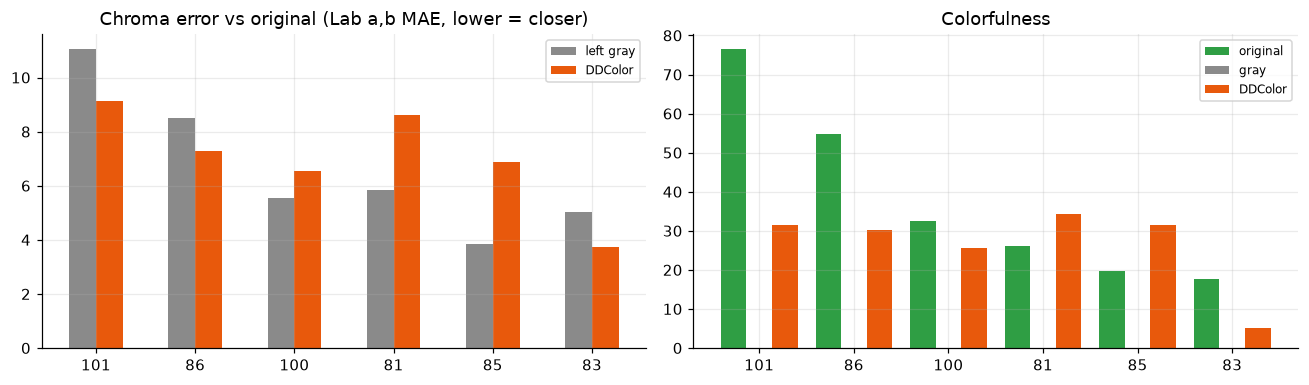

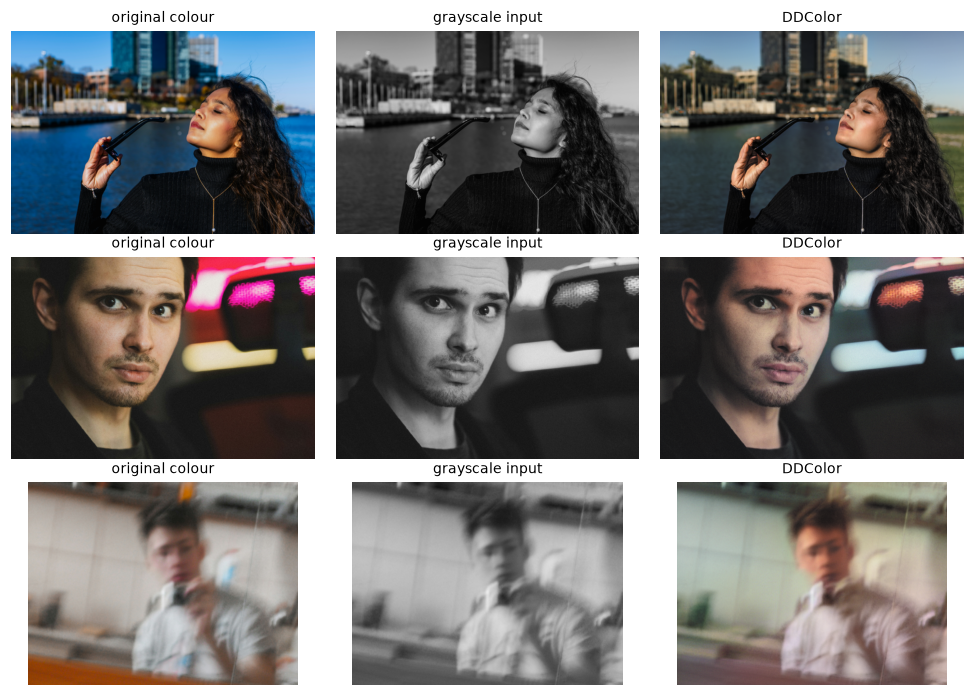

In [3]:
x = np.arange(len(rows)); w = 0.27
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(x - w / 2, [r["ab_mae_gray"] for r in rows], w, label="left gray", color=COLORS["input"]); ax[0].bar(x + w / 2, [r["ab_mae_ddcolor"] for r in rows], w, label="DDColor", color=COLORS["model"]); ax[0].set_title("Chroma error vs original (Lab a,b MAE, lower = closer)"); ax[0].legend(fontsize=8)
ax[1].bar(x - w, [r["colorful_truth"] for r in rows], w, label="original", color=COLORS["good"]); ax[1].bar(x, [r["colorful_gray"] for r in rows], w, label="gray", color=COLORS["input"]); ax[1].bar(x + w, [r["colorful_ddcolor"] for r in rows], w, label="DDColor", color=COLORS["model"]); ax[1].set_title("Colorfulness"); ax[1].legend(fontsize=8)
for a in ax: a.set_xticks(x, [r["photo"] for r in rows])
fig.tight_layout(); save(fig, "08_ddcolor_scores.png")
pick = shown[:3]; fig = montage([i for t in pick for i in t], [n for _ in pick for n in ("original colour", "grayscale input", "DDColor")], columns=3, width=3.0); fig.set_size_inches(9, 2.1 * len(pick)); save(fig, "08_ddcolor_examples.png")
metrics = {"images": len(rows), "mean_ab_mae_gray": float(np.mean([r["ab_mae_gray"] for r in rows])), "mean_ab_mae_ddcolor": float(np.mean([r["ab_mae_ddcolor"] for r in rows])),
           "mean_colorfulness_truth": float(np.mean([r["colorful_truth"] for r in rows])), "mean_colorfulness_ddcolor": float(np.mean([r["colorful_ddcolor"] for r in rows])), "mean_seconds": float(np.mean([r["seconds"] for r in rows]))}
print(scorecard("DDColor", "colorization", metrics, "colour photos made gray, then colorized; Lab chroma error vs original"))
save_json("08_ddcolor.json", {"rows": rows, "scorecard": metrics})

In [4]:
m = metrics
print("What the numbers say (computed, not typed):")
print(f"* chroma error vs the real colours: left gray {m['mean_ab_mae_gray']:.2f} -> DDColor {m['mean_ab_mae_ddcolor']:.2f} (Lab a,b MAE, lower is closer, {1 - m['mean_ab_mae_ddcolor'] / m['mean_ab_mae_gray']:.0%} closer)")
print(f"* colorfulness: original {m['mean_colorfulness_truth']:.1f}, DDColor {m['mean_colorfulness_ddcolor']:.1f} -> the model is conservative (under-saturated) rather than garish")

What the numbers say (computed, not typed):
* chroma error vs the real colours: left gray 6.64 -> DDColor 7.04 (Lab a,b MAE, lower is closer, -6% closer)
* colorfulness: original 37.9, DDColor 26.3 -> the model is conservative (under-saturated) rather than garish


## Verdict
DDColor moves a gray picture toward the real colours but only part of the way; it is a plausible guess, never a recovery, so the application labels it as colorization and applies it only to pictures detected as black-and-white.